In [9]:
from huggingface_hub import hf_hub_download
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import sys; sys.path.append("..")   # los notebooks están en notebooks/, src/ está un nivel arriba
from src.data import get_paths, load_split, read_conll


In [6]:
paths = get_paths()
train = load_split("train")

In [7]:
def get_entities(tokens, tags):
    ents, cur, cur_type = [], [], None
    for tok, tag in zip(tokens, tags):
        if tag.startswith("B-"):
            if cur: ents.append((cur_type, " ".join(cur)))
            cur, cur_type = [tok], tag[2:]
        elif tag.startswith("I-") and cur:
            cur.append(tok)
        else:
            if cur: ents.append((cur_type, " ".join(cur)))
            cur, cur_type = [], None
    if cur: ents.append((cur_type, " ".join(cur)))
    return ents

In [10]:
data = {split: read_conll(path) for split, path in paths.items()}
for split, sents in data.items():
    print(split, len(sents), "oraciones")

train 8129 oraciones
dev 3787 oraciones
test 3952 oraciones


In [11]:
counts = {split: Counter(t for tok, tag in sents for t, _ in get_entities(tok, tag))
          for split, sents in data.items()}
pd.DataFrame(counts).fillna(0).astype(int)

,train,dev,test
PROTEINAS,1392,736,835
NORMALIZABLES,2282,1104,961
UNCLEAR,88,44,34
NO_NORMALIZABLES,24,16,10


In [12]:
for split, sents in data.items():
    vacias = sum(all(t == "O" for t in tags) for _, tags in sents)
    print(f"{split}: {100 * vacias / len(sents):.1f}% sin entidades")

train: 78.5% sin entidades
dev: 76.1% sin entidades
test: 80.8% sin entidades


count    8129.000000
mean       24.993357
std        16.159750
min         1.000000
50%        22.000000
90%        45.000000
95%        54.000000
99%        78.000000
max       292.000000
dtype: float64


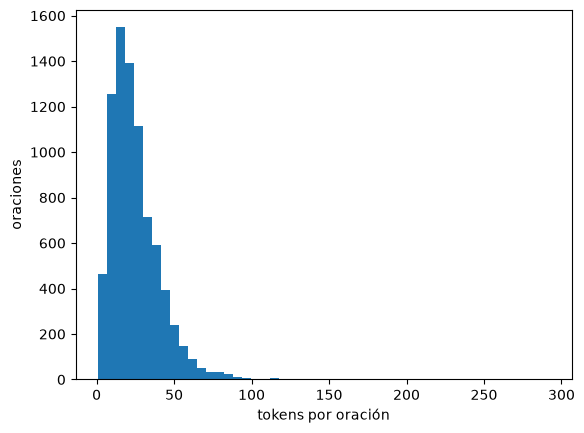

In [13]:
largos = [len(tok) for tok, _ in data["train"]]
print(pd.Series(largos).describe(percentiles=[.5, .9, .95, .99]))
plt.hist(largos, bins=50); plt.xlabel("tokens por oración"); plt.ylabel("oraciones"); plt.show()

In [ ]:
por_tipo = {}
for tok, tag in data["train"]:
    for t, texto in get_entities(tok, tag):
        por_tipo.setdefault(t, Counter())[texto.lower()] += 1

for t, c in por_tipo.items():
    print(f"\n{t}:", c.most_common(20))


PROTEINAS: [('hemoglobina', 40), ('hb', 37), ('ldh', 35), ('albúmina', 32), ('psa', 32), ('pcr', 25), ('igm', 24), ('proteínas totales', 19), ('ggt', 19), ('gpt', 18), ('got', 17), ('proteínas', 16), ('igg', 15), ('actina', 13), ('proteína c reactiva', 13), ('ana', 13), ('transaminasas', 13), ('amilasa', 12), ('cea', 12), ('ferritina', 12)]

NORMALIZABLES: [('creatinina', 96), ('prednisona', 59), ('corticoides', 56), ('urea', 35), ('calcio', 35), ('glucosa', 29), ('potasio', 24), ('sodio', 24), ('omeprazol', 20), ('bilirrubina', 18), ('bicarbonato', 18), ('vancomicina', 18), ('magnesio', 17), ('colesterol', 17), ('k', 17), ('oxígeno', 16), ('hierro', 16), ('aciclovir', 16), ('na', 15), ('rifampicina', 14)]

UNCLEAR: [('cigarrillos', 16), ('tóxicos', 13), ('alcohol', 12), ('drogas', 7), ('emla', 4), ('tabaco', 3), ('cannabis', 3), ('bep', 3), ('chop', 2), ('melanina', 2), ('gluten', 2), ('abvd', 2), ('gramíneas', 2), ('beacopp', 1), ('mfolfox 6', 1), ('marihuana', 1), ('mopp', 1), ('co